<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_08/5Magenta_art_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Aplicação de Estilos em Imagens**  

Neste notebook você empregará um modelo de **Deep Learning** pré-treinado para aplicar *estilos* a uma imagem original. Algo semelhante pode ser empregado também para vídeos e som.

# AdaIN

Este é um modelo baseado no método *Adaptive Instance Normalization* (AdaIN), introduzido em:

> Huang & Belongie (2017) — **Arbitrary Style Transfer in Real-Time with Adaptive Instance Normalization** https://doi.org/10.1109/ICCV.2017.167.

<img src="https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/imgSource/AdaIN.png" width=400> 

O **AdaIN** permite **transferir qualquer estilo arbitrário** para uma imagem de conteúdo em tempo real, sem precisar treinar um modelo separado para cada estilo.

A arquitetura é composta por três partes principais:

1. **Encoder (VGG pré-treinada e congelada):** extrai os mapas de características das imagens de *conteúdo* e de *estilo*.

2. **Camada AdaIN:** ajusta, canal a canal, a média ($\mu$) e o desvio padrão ($\sigma$) dos `mapas de ativação` do conteúdo para coincidir com às estatísticas do estilo, preservando a estrutura espacial da cena.

3. **Decoder (CNN treinada):** reconstrói a imagem final a partir dos mapas de ativação transformados.

Intuitivamente, o modelo pega a imagem de **conteúdo** (por meio dos seus mapas de ativação) e ajusta sua média e variância para bater com as da imagem de **estilo**.

<img src="https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/imgSource/ex_adaIN.jpg" width=600> 

## Etapa 1: Cálculo das estatísticas por canal.

Dado um mapa de ativações do `conteúdo` $F_c \in \mathbb{R}^{C \times H \times W}$ e do `estilo` $F_s \in \mathbb{R}^{C \times H \times W}$, calculam-se, para cada canal $c$, a média e o desvio padrão:

$$\mu(F_c), \sigma(F_c) \quad \quad \quad \quad  \mu(F_s), \sigma(F_s) $$

## Etapa 2: Normalização do conteúdo.

Primeiro normaliza-se o mapa de ativações do conteúdo, removendo suas
estatísticas originais:

$$
\hat{F}_c =
\frac{F_c - \mu(F_c)}{\sigma(F_c)}.
$$


## Etapa 3: Aplicação das estatísticas do estilo (AdaIN).

As características normalizadas do conteúdo são então reescaladas e
deslocadas utilizando as estatísticas do estilo:

$$
F_{\text{stylized}} =
\sigma(F_s)\,\hat{F}_c + \mu(F_s).
$$

Esse tensor $F_{\text{stylized}}$ contém o conteúdo original com o estilo imposto
no espaço de características.


# Transferência de Estilo

De modo simples, a ideia modelo generativo para aplicação de estilos é a de aplicar a mesma  distribuição de probabilidade, as mesmas estatísticas, dos dados da imagem estilo à imagem original. Essas estatísticas são extraídas das imagens usando uma **rede neural Convolucional**.



> Para Saber Mais

Se você quiser saber mais sobre essa técnica  você pode começar por aqui:

* Fritz Lab, [**Style Transfer Guide**](https://www.fritz.ai/style-transfer/)
* TensorFlow, [**Neural style transfer**](https://www.tensorflow.org/tutorials/generative/style_transfer)

# Magenta

`Magenta` é um projeto de código aberto da **Google IA** que emprega o aprendizado de máquina, mais particularmente Deep Learning, para **gerar arte**. Atualmente o projeto suporta aplicação de estilo em imagens e a produção de *scketchs* (desenhos semelhantes a esboços manuais feitos por um ser humano), mas também a produção de *música generativa*! Você pode acessar mais sobre o projeto `Magenta` [aqui](https://magenta.tensorflow.org/).

O modelo `arbitrary-image-stylization-v1-256` e a adaptação do artigo de Huang & Belongie (2017) publicado no TensorFlow Hub.


In [1]:
#@markdown
from IPython.display import IFrame
IFrame("https://magenta.tensorflow.org/", 800,500)

# Imports

Além dos imports básicos como o `NumPy` e `Matplotlib`, importamos o `TensorFlow` e o `TensorFlow Hub`

[TensorFlow](https://www.tensorflow.org/)  é uma plataforma de código aberto de ponta a ponta para aprendizado de máquina, particularmente para implementação de modelos de redes neurais profundas. Juntamente com [PyTorch](https://pytorch.org) é um dos principais *frameworks* empregados no desenvolvimento de redes *deep learning*. O Magenta disponibiliza modelos baseados em redes neurais convolucionais (as mais empregadas no processamento de imagens) desenvolvidos no ecossistema TensorFlow para transferência de estilo em imagens.

O [TensorFlow Hub](https://www.tensorflow.org/hub) é um repositório de modelos de aprendizado de máquina pré treinados, prontos para ajustes finos (_fine tunning_) e implantáveis ​​em qualquer lugar. O `Magenta` é um dos modelos pré treinados que encontramos para uso público no TensorFlow Hub.

Este exemplo foi contruído e validado nas versões:
```
TF Version:  2.8.2
TF Hub version:  0.12.0
```

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
import tensorflow_hub as hub

print("TF Version: ", tf.__version__)
print("TF Hub version: ", hub.__version__)
print("GPU available: ", tf.config.list_physical_devices('GPU')) # havendo disponibilidade o modelo executa empregando GPU


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TF Version:  2.21.0
TF Hub version:  0.16.1
GPU available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## OpenCV

Aqui empregamos o OpenCV apenas para fazer o resize da imagem estilo para a altura da imagem original mantendo as suas proporções. O tamanho da imagem original será mantido e empregado na imagem estilizada. A menos que tenha interesse, você não precisa se preocupar com este código.


In [ ]:
#@markdown resize image
# source: https://stackoverflow.com/questions/44650888/resize-an-image-without-distortion-opencv
import cv2
def image_resize(image, width = None, height = None, inter = cv2.INTER_AREA):

    # initialize the dimensions of the image to be resized and grab the image size
    dim = None
    (h, w) = image.shape[:2]

    # if both the width and height are None, then return the original image
    if width is None and height is None:
        return image

    # check to see if the width is None
    if width is None:
        # calculate the ratio of the height and construct the dimensions
        r = height / float(h)
        dim = (int(w * r), height)

    # otherwise, the height is None
    else:
        # calculate the ratio of the width and construct the dimensions
        r = width / float(w)
        dim = (width, int(h * r))

    # resize the image
    resized = cv2.resize(image, dim, interpolation = inter)

    # return the resized image
    return resized

# Aplicando o Modelo `Magenta` para transferência de Estilos

A função abaixo retorna uma imagem estilizada a partir de uma imagem de *conteúdo* (`content_image`) e de uma imagem de *estilo* (`style_image`). O fluxo segue estes passos:

1. Converte as imagens de entrada em **tensores** (*arrays* multidimensionais operados pelo `TensorFlow`).
2. Carrega o modelo **pré-treinado** do `Magenta` para transferência de estilo.
3. Executa a rede **pré-treinada** **às** imagens fornecidas (`content_image` e `style_image`).
4. Converte o tensor/array resultante de volta para uma matriz de pixels.

In [ ]:
def generate_stylized(content_image,style_image):

  # Converte a matriz de imagens em matriz de tensores normalizadas
  content_image = content_image.astype(np.float32)[np.newaxis, ...] / 255.
  style_image = style_image.astype(np.float32)[np.newaxis, ...] / 255.

  # Carrega o modelo pré-treinado de estilização do TensorFlow Hub
  hub_module = hub.load('https://tfhub.dev/google/magenta/arbitrary-image-stylization-v1-256/2')

  # Aplica o modelo às imagens de conteúdo e estilo 
  outputs = hub_module(tf.constant(content_image), tf.constant(style_image))
  stylized_image = outputs[0]

  stylized_image = np.array(stylized_image)

  # redimensiona a matriz para obter a imagem estilizada
  stylized_image = stylized_image.reshape(stylized_image.shape[1],stylized_image.shape[2],stylized_image.shape[3])

  return stylized_image

# Exemplo: **O Mackenzie *pintado* por Kandinsky e Tarsila**

## Carregar as imagens

Vamos trazer uma imagem do Mackenzie e aplicar o estilo de duas pinturas famosas de *Kandinsky* e a brasileira *Tarsila*. Mais adiante haverá um código para você fazer o upload das imagens a partir de  arquivos locais da sua máquina.

In [5]:
!wget https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/adaIN/mackenzie.jpg
!wget https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/adaIN/Kandinsky.jpg
!wget https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/adaIN/Tarsila.jpg

!ls /content


--2026-11-24 15:15:45--  https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/adaIN/mackenzie.jpg
Resolving github.com (github.com)... 48.200.82.112
Connecting to github.com (github.com)|48.200.82.112|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/adaIN/mackenzie.jpg [following]
--2026-11-24 15:15:45--  https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/adaIN/mackenzie.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 199513 (195K) [image/jpeg]
Saving to: ‘mackenzie.jpg’

mackenzie.jpg       100%[===================>] 194.84K  --.-KB/s    in 0.02s   

2026-11-24 15:15:45 (8.95 MB/s) - ‘mackenzie.jpg’ saved [199513/19

## Aplicação do Estilo

Fazemos o resize da imagem de estilo para ajustar a nossa imagem original de conteúdo. Aplicamos a nossa função para gerar a imagem estilizada e, em seguida, podemos exibir as imagens empregadas e a estilizada.

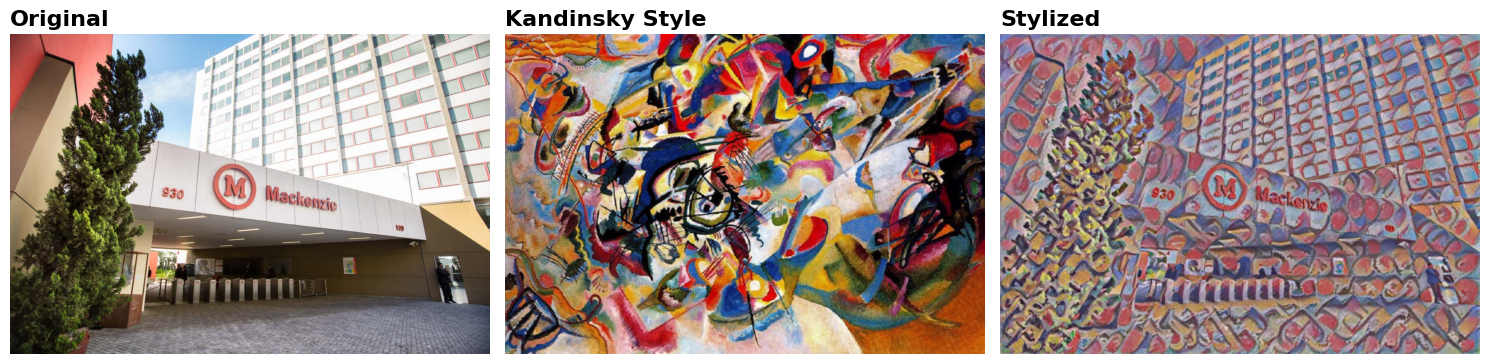

In [6]:
content_image = plt.imread('/content/mackenzie.jpg')
style_image = plt.imread('/content/Kandinsky.jpg')

# resize
style_image = image_resize(style_image, height=content_image.shape[0])

# stylized
stylized_image = generate_stylized(content_image,style_image)

# plot
fig, ax = plt.subplots(1,3,figsize=(15,5))

ax[0].imshow(content_image)
ax[0].set_title('Original', fontsize=16, loc='left', weight='bold')
ax[0].set_axis_off()

ax[1].imshow(style_image)
ax[1].set_title('Kandinsky Style', fontsize=16, loc='left', weight='bold')
ax[1].set_xlim([0,content_image.shape[1]])
ax[1].set_axis_off()

ax[2].imshow(stylized_image)
ax[2].set_title('Stylized', fontsize=16, loc='left', weight='bold')
ax[2].set_axis_off()

plt.tight_layout()
plt.show()


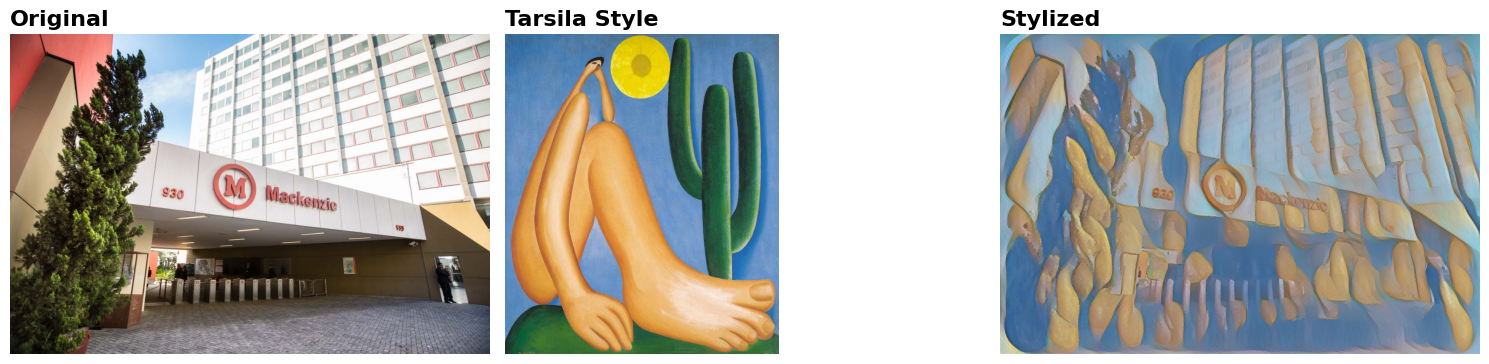

In [7]:
content_image = plt.imread('/content/mackenzie.jpg')
style_image = plt.imread('/content/Tarsila.jpg')

# resize
style_image = image_resize(style_image, height=content_image.shape[0])

# stylized
stylized_image = generate_stylized(content_image,style_image)

# plot
fig, ax = plt.subplots(1,3,figsize=(15,5))

ax[0].imshow(content_image)
ax[0].set_title('Original', fontsize=16, loc='left', weight='bold')
ax[0].set_axis_off()

ax[1].imshow(style_image)
ax[1].set_title('Tarsila Style', fontsize=16, loc='left', weight='bold')
ax[1].set_xlim([0,content_image.shape[1]])
ax[1].set_axis_off()

ax[2].imshow(stylized_image)
ax[2].set_title('Stylized', fontsize=16, loc='left', weight='bold')
ax[2].set_axis_off()

plt.tight_layout()
plt.show()


## Salvando as Imagens

Você pode empregar:

In [8]:
fig.savefig('all_figs.jpg',bbox_inches='tight')

para salvar as imagens de forma conjunta. Ou,

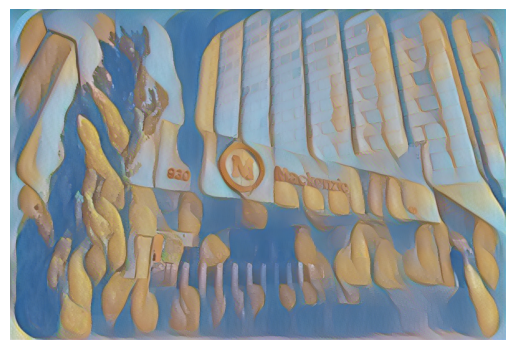

In [9]:
fig, ax = plt.subplots()
ax.imshow(stylized_image)
ax.set_axis_off()

plt.savefig('stylized.jpg',bbox_inches='tight')

para salvar a imagem estilizada de forma isolada.

## Download

Para fazer o download da imagem desejada você pode empregar:

In [13]:
from google.colab import files

files.download('stylized.jpg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Crie você agora a sua arte...

## Upload images

Você pode empregar o código abaixo para fazer o upload das suas imagens aqui (ou se quiser buscar uma imagem da internet empregue o comando `!wget` como fizemos acima).

In [11]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving man-6706413_1280.jpg to man-6706413_1280.jpg
User uploaded file "man-6706413_1280.jpg" with length 213569 bytes


Empregue o código que empregamos para criação das imagens estilizadas no exemplo.

In [12]:
# Your code
